# FMT response — strain-sharing stats & random-effects meta-analysis

1. Load & prepare data
2. Config + shared helpers (one meta-analysis implementation used everywhere)
3. **A.** Per-stat combined figure (boxplot + forest) for every stat
4. **B.** DoSER: boxplots (cancer / non-cancer), forest plots, summary table
5. **C.** DoSER forest (grouped) + diamonds-only panel for the other stats
6. Per-indication subgroup summary (CSV)

## 1. Load & prepare data

In [1]:
import os
import ast
import warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patheffects as pe
import matplotlib.transforms as transforms
from matplotlib.patches import Patch
from scipy import stats
from scipy.stats import mannwhitneyu, norm
plt.rcParams['svg.fonttype'] = 'none'

warnings.filterwarnings('ignore')

In [2]:
# ── Load ─────────────────────────────────────────────────────────────────────
sgb_list = pd.read_csv('/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/doser_results_for_engraftment_Oct26.csv')
sgb_list['doser'] = pd.to_numeric(sgb_list['doser'], errors='coerce')

metadata = pd.read_csv('/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/strain_share_newrun_June26/triads_cleaned_1gbp.csv')

# ── Attach dataset / success labels from metadata ────────────────────────────
post_map = (
    metadata.drop_duplicates(subset='single_post_sample')
    .set_index('single_post_sample')[['display_dataset', 'success']]
)
merged = sgb_list.copy()
merged['display_dataset'] = merged['post_fmt_id'].map(post_map['display_dataset'])
merged['success']         = merged['post_fmt_id'].map(post_map['success'])

print("Unmatched rows:", merged['display_dataset'].isna().sum())

Unmatched rows: 0


In [3]:
# ── Strain-level metrics ─────────────────────────────────────────────────────
# Pre-FMT denominator (n_pre): every pre-FMT SGB is in exactly one state
#     retained (same strain post) + swapped (different strain post) + lost (absent post) = n_pre
# Post-FMT denominator (n_post): acquisition metrics, describing the post-FMT community.

def parse_sgb_set(val) -> set:
    if isinstance(val, (set, list, tuple)):
        return set(val)
    if pd.isna(val) or val == "" or val == "NaN":
        return set()
    s = str(val).strip()
    if s.startswith("[") or s.startswith("{"):
        try:
            return set(ast.literal_eval(s))
        except Exception:
            pass
    return {x.strip() for x in s.split(",") if x.strip()}


def safe_div(num, den):
    return num / den if den and den > 0 else float("nan")

# ── Drop excluded pre-FMT samples ────────────────────────────────────────────
exclude_pre_fmt_ids = [
#     "SRR14871871",
#     "SRR14872202",
#     "SRR14872194",
]

n_before = len(merged)
merged = merged[~merged["pre_fmt_id"].isin(exclude_pre_fmt_ids)].copy()

print(f"Dropped {n_before - len(merged)} rows with excluded pre_FMT_id values.")

rows = []
for _, row in merged.iterrows():
    post_sgbs = parse_sgb_set(row["post_sgbs"])
    pre_sgbs  = parse_sgb_set(row["pre_sgbs"])

    n_post              = row["n_post_sgbs"]
    n_pre               = row["n_pre_sgbs"]
    n_shared_donor_post = row["n_shared_donor_post"]
    n_shared_post_pre   = row["n_shared_post_pre"]   # pre SGBs whose strain persists post-FMT
    n_post_not_donor    = n_post - n_shared_donor_post

    n_lost         = len(pre_sgbs - post_sgbs)
    n_name_overlap = len(post_sgbs & pre_sgbs)
    n_swapped_raw  = n_name_overlap - n_shared_post_pre
    n_swapped      = max(n_swapped_raw, 0)
    n_other        = max(n_post_not_donor - n_swapped, 0)

    rows.append({
        # post-FMT denominator (acquisition)
        "perc_acq_donor_strains":      safe_div(n_shared_donor_post, n_post),
        "perc_acq_other_strains":      safe_div(n_other, n_post),
        # pre-FMT denominator (fate of recipient's own SGBs)
        "perc_strains_retained":       safe_div(n_shared_post_pre, n_pre),
        "perc_strains_swapped":        safe_div(n_swapped, n_pre),
        "perc_sgbs_lost":              safe_div(n_lost, n_pre),
        "perc_strains_lost":           safe_div(n_lost + n_swapped, n_pre),   # = 1 - retained
        # share of the post-FMT community that is recipient-derived (reference only)
        "perc_post_recipient_derived": safe_div(n_shared_post_pre, n_post),
        # QC flags: retained + swapped + lost should equal n_pre
        "qc_partition_ok":             (n_shared_post_pre + n_swapped + n_lost) == n_pre,
        "qc_swapped_clipped":          n_swapped_raw < 0,
    })

metrics_df = pd.DataFrame(rows, index=merged.index)
merged = merged.drop(columns=[c for c in metrics_df.columns if c in merged.columns]).join(metrics_df)

# ── QC report ────────────────────────────────────────────────────────────────
valid_pre = merged["n_pre_sgbs"] > 0
n_bad_partition = int((~merged.loc[valid_pre, "qc_partition_ok"]).sum())
n_clipped = int(merged["qc_swapped_clipped"].sum())

print(f"Samples: {len(merged)}")
print(f"  n_pre = 0 (pre-FMT metrics set to NaN): {int((~valid_pre).sum())}")
print(f"  Partition violated (retained+swapped+lost != n_pre): {n_bad_partition}")
print(f"  Swapped count clipped at 0 (name overlap < shared_post_pre): {n_clipped}")
if n_bad_partition or n_clipped:
    print("  -> Inspect these rows: upstream strain-sharing counts are inconsistent with the SGB lists.")
    print(merged.loc[valid_pre & (~merged["qc_partition_ok"] | merged["qc_swapped_clipped"]),
                     ["n_pre_sgbs", "n_post_sgbs", "n_shared_post_pre", "qc_partition_ok", "qc_swapped_clipped"]
                     ].head(20).to_string())

Dropped 0 rows with excluded pre_FMT_id values.
Samples: 598
  n_pre = 0 (pre-FMT metrics set to NaN): 0
  Partition violated (retained+swapped+lost != n_pre): 0
  Swapped count clipped at 0 (name overlap < shared_post_pre): 0


In [4]:
# ── Analysis table: fmt_merged ───────────────────────────────────────────────
indication_map = {
    'AggarwalaV_2021':        'CDiff',
    'IaniroG_2022_Cdiff':     'CDiff',
    'SmillieC_2018':          'CDiff',
    'BaruchE_2020':           'Cancer',
    'ChenK_2026':             'Cancer',
    'DavarD_2021':            'Cancer',
    'DuttaguptaS_2026_Mel':   'Cancer',
    'DuttaguptaS_2026_NSCLC': 'Cancer',
    'FernandesR_2026':        'Cancer',
    'PorcariS_2026':          'Cancer',
    'RoutyB_2023':            'Cancer',
    'BarYosephH_2020':        'MDRO',
    'WoodworthM_2023':        'MDRO',
    'IaniroG_2022_MDRB':      'MDRO',
    'OrbergET_2025_C':        'GvHD',
    'ReddiS_2025':            'GvHD',
    'ShekarrizS_2025':        'IBD (UC)',
    'LeeS_2017':              'IBD (UC)',
    'DammanC_2015':           'IBD (UC)',
    'SuskindD_2015':          'IBD (CD)',
    'VaughnB_2016':           'IBD (CD)',
    'GollR_2020':             'IBS',
    'IaniroG_2020':           'TKI induced diarrhea',
    'QinP_2025':              'Psoriatic arthritis',
    'ZhaoH_2020':             'Tourettes',
}

SUCCESS_MAP = {
    'TRUE': True, 'True': True, 'true': True, 'YES': True, 'Yes': True, 'yes': True, '1': True, 1: True, True: True,
    'FALSE': False, 'False': False, 'false': False, 'NO': False, 'No': False, 'no': False, '0': False, 0: False, False: False,
}


fmt_merged = merged.copy()
# fmt_merged = fmt_merged[fmt_merged['dataset'] != 'ReddiS_2025'].copy()
fmt_merged['dataset']    = fmt_merged['display_dataset']
fmt_merged['indication'] = fmt_merged['dataset'].map(indication_map)
fmt_merged['success']    = fmt_merged['success'].map(SUCCESS_MAP)
fmt_merged = fmt_merged.dropna(subset=['success'])          # drop rows with no success label

print(fmt_merged['success'].value_counts(dropna=False))
print(fmt_merged.groupby(['dataset', 'success']).size().unstack(fill_value=0))

success
True     207
False    118
Name: count, dtype: int64
success                 False  True 
dataset                             
AggarwalaV_2021             2      7
BarYosephH_2020             1      6
BaruchE_2020                7      3
ChenK_2026                  4      7
DammanC_2015                5      1
DavarD_2021                 7      6
DuttaguptaS_2026_Mel        5     14
DuttaguptaS_2026_NSCLC      3     15
FernandesR_2026             9      9
GollR_2020                  6     14
HouriganS_2019              0      8
IaniroG_2020                1      5
IaniroG_2022_Cdiff          1     14
IaniroG_2022_IBD            1      1
IaniroG_2022_MDRB           2      2
KongL_2020                  7      0
MossE_2017                  0      2
PodlesnyD_2020              0      8
PorcariS_2026              10     10
QinP_2025                   6      6
ReddiS_2025                 3     14
RossenN_2015                2      2
RoutyB_2023                 6     10
SchmidtT_2022_U

## 2. Config + shared helpers

In [5]:
# ══════════════════════════════════════════════════════════════════════════
# CONFIG
# ══════════════════════════════════════════════════════════════════════════
stats_to_test = [
    'perc_acq_donor_strains',
    'perc_sgbs_lost',
    'perc_strains_retained',
    'perc_strains_swapped',
    'perc_acq_other_strains',
    'perc_strains_lost',
    'doser',
]
OTHER_STATS = [s for s in stats_to_test if s != 'doser']     # everything except doser

# Titles used on the per-stat combined figure (A) and the old-style DoSER forest
STAT_TITLES = {
    'perc_acq_donor_strains': 'Donor Strain Acquisition',
    'perc_sgbs_lost':         'SGB Loss Rate',
    'perc_strains_retained':  'Pre-FMT Strain Retention',
    'perc_strains_swapped':   'Strain Swapping Rate',
    'perc_acq_other_strains': 'Acquisition of Non-Donor Strains',
    'perc_strains_lost':      'Overall Strain Loss',
    'doser':                  'Donor Strain Engraftment Rate (DoSER)',
}

# QUICK-EDIT: stat display names on the diamonds-only panel
STAT_LABELS = {
    'doser':                  'DoSER',
    'perc_acq_donor_strains': 'Percentage of Donor Strains',
    'perc_sgbs_lost':         'Pre-FMT Species Loss Rate',
    'perc_strains_retained':  'Pre-FMT Strain Retention',
    'perc_strains_swapped':   'Strain Swapping Rate',
    'perc_acq_other_strains': 'Acquisition of Non-Donor Strains',
    'perc_strains_lost':      'Overall Strain Loss',
}

# Colours
COLOR_SUCCESS   = '#74B700'
COLOR_FAILURE   = '#A95FBA'
CANCER_COLOR    = '#e74c3c'
NONCANCER_COLOR = '#2980b9'
DIAMOND_COLOR   = '#8e44ad'

# Output
OUT_DIR  = os.getcwd()
SAVE_DIR = os.path.join(OUT_DIR, 'figs')
os.makedirs(SAVE_DIR, exist_ok=True)

# Figure geometry
FOREST_FIGSIZE = (8, 7)
FOREST_XLIM    = (-4, 4)

# Condensed boxplots: 85 x 50 mm, Arial 5 pt (scoped via rc_context so other figures are untouched)
BOX_FIGSIZE         = (85 / 25.4, 50 / 25.4)
BOX_SPACING         = 0.9
DATASET_GAP_DEFAULT = 2.5
SHARED_AXES_RECT    = (0.18, 0.42, 0.99, 0.99)     # (left, bottom, right, top) — same for every panel
BOX_FONT_SIZE       = 5
BOX_RC = {
    'font.family':     'sans-serif',
    'font.sans-serif': ['Arial', 'Liberation Sans', 'Helvetica', 'DejaVu Sans'],   # falls back if Arial is missing
    'font.size':       BOX_FONT_SIZE,
}

In [6]:
# ══════════════════════════════════════════════════════════════════════════
# HELPERS — one implementation of everything that used to be copy-pasted
# ══════════════════════════════════════════════════════════════════════════
dataset_indication = fmt_merged.drop_duplicates('dataset').set_index('dataset')['indication'].to_dict()

def is_cancer(dataset):
    return dataset_indication.get(dataset) == 'Cancer'

def filter_heterogeneous(d):
    """Keep datasets with >1 sample and both success and failure present."""
    counts = d.groupby('dataset')['success'].agg(['count', 'nunique'])
    keep = counts[(counts['nunique'] > 1) & (counts['count'] > 1)].index
    return d[d['dataset'].isin(keep)].copy()

def sig_stars(p, ns='ns'):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ns

def fmt_p(p, label=True, sep=''):
    """label=True: 'p=0.0123' / 'p<0.0001' (sep=' ' gives 'p = 0.0123').  label=False: '0.0123' / '<0.0001'."""
    op, val = ('<', '0.0001') if p < 0.0001 else ('=', f'{p:.4f}')
    if label:
        return f"p{sep}{op}{sep}{val}"
    return f"<{val}" if op == '<' else val


def hedges_g(mean1, mean2, sd1, sd2, n1, n2):
    if n1 + n2 - 2 <= 0:
        return np.nan, np.nan
    sp = np.sqrt(((n1 - 1) * sd1**2 + (n2 - 1) * sd2**2) / (n1 + n2 - 2))
    if sp == 0:
        return np.nan, np.nan
    d  = (mean1 - mean2) / sp
    df = n1 + n2 - 2
    J  = 1 - (3 / (4 * df - 1))
    g  = d * J
    var_g = (n1 + n2) / (n1 * n2) + g**2 / (2 * (n1 + n2))
    return g, var_g


def meta_analyze(data, stat, verbose=False):
    """Per-dataset Hedges' g (success − failure) + DerSimonian-Laird random-effects pooling.
    Always returns a dict (pooled fields are NaN when fewer than 2 datasets are estimable)."""
    stat_data = data.dropna(subset=[stat])

    rows = []
    for dataset in sorted(stat_data['dataset'].unique()):
        d    = stat_data[stat_data['dataset'] == dataset]
        succ = d[d['success'] == True][stat]
        fail = d[d['success'] == False][stat]
        n1, n2 = len(succ), len(fail)
        if n1 < 1 or n2 < 1:
            continue
        g, var_g = hedges_g(succ.mean(), fail.mean(),
                            succ.std(ddof=1) if n1 > 1 else 0.0,
                            fail.std(ddof=1) if n2 > 1 else 0.0,
                            n1, n2)
        if np.isnan(g) or np.isnan(var_g) or var_g <= 0:
            if verbose:
                print(f"  Skipping {dataset}: cannot compute Hedges' g")
            continue
        se_g = np.sqrt(var_g)
        rows.append({
            'dataset': dataset, 'n_succ': n1, 'n_fail': n2,
            'mean_succ': succ.mean(), 'mean_fail': fail.mean(),
            'g': g, 'var_g': var_g, 'se_g': se_g,
            'ci_lo': g - 1.96 * se_g, 'ci_hi': g + 1.96 * se_g,
            'p_val': 2 * (1 - norm.cdf(abs(g / se_g))),
            'weight_fe': 1.0 / var_g,
        })
    meta_df = pd.DataFrame(rows)

    out = dict(meta_df=meta_df, k=len(meta_df), g_re=np.nan, ci_lo_re=np.nan, ci_hi_re=np.nan,
               p_re=np.nan, tau2=np.nan, Q=np.nan, df_Q=np.nan, p_Q=np.nan, I2=np.nan)

    if len(meta_df) >= 2:
        k    = len(meta_df)
        w    = meta_df['weight_fe'].values
        g_fe = np.sum(w * meta_df['g'].values) / np.sum(w)
        Q    = np.sum(w * (meta_df['g'].values - g_fe) ** 2)
        df_Q = k - 1
        C    = np.sum(w) - np.sum(w ** 2) / np.sum(w)
        tau2 = max(0, (Q - df_Q) / C)

        meta_df['var_re'] = meta_df['var_g'] + tau2
        meta_df['w_re']   = 1.0 / meta_df['var_re']
        W_re  = meta_df['w_re'].sum()
        g_re  = (meta_df['w_re'] * meta_df['g']).sum() / W_re
        se_re = np.sqrt(1.0 / W_re)
        meta_df['pct_weight'] = meta_df['w_re'] / W_re * 100
        out.update(g_re=g_re, ci_lo_re=g_re - 1.96 * se_re, ci_hi_re=g_re + 1.96 * se_re,
                   p_re=2 * (1 - norm.cdf(abs(g_re / se_re))), tau2=tau2, Q=Q, df_Q=df_Q,
                   p_Q=1 - stats.chi2.cdf(Q, df_Q),
                   I2=max(0, (Q - df_Q) / Q * 100) if Q > 0 else 0.0)
    elif len(meta_df) == 1:
        meta_df['pct_weight'] = np.nan
    return out


def print_meta(res):
    meta_df = res['meta_df']
    if len(meta_df) < 2:
        print("  Insufficient studies for meta-analysis.")
        return
    print(f"\n  {'Dataset':<25} {'g':>7} {'95% CI':>22} {'p':>8} {'Weight%':>8}")
    print("  " + "-" * 72)
    for _, r in meta_df.iterrows():
        ci = f"[{r['ci_lo']:+.3f}, {r['ci_hi']:+.3f}]"
        print(f"  {r['dataset']:<25} {r['g']:>+7.3f} {ci:>22} {fmt_p(r['p_val'], label=False):>8} {r['pct_weight']:>7.1f}%")
    print("  " + "-" * 72)
    ci = f"[{res['ci_lo_re']:+.3f}, {res['ci_hi_re']:+.3f}]"
    print(f"  {'POOLED (RE)':<25} {res['g_re']:>+7.3f} {ci:>22} {fmt_p(res['p_re'], label=False):>8}")
    print(f"\n  τ²={res['tau2']:.4f}  Q({res['df_Q']})={res['Q']:.2f}, p={res['p_Q']:.4f}  I²={res['I2']:.1f}%")


def mann_whitney_by_dataset(stat_data, stat, datasets, verbose=False):
    """Two-sided Mann-Whitney U (success vs failure) per dataset; needs >=2 per arm."""
    if verbose:
        print(f"\n  {'Dataset':<30} {'n_succ':>7} {'n_fail':>7} {'U':>8} {'p':>8} {'sig':>5}")
        print("  " + "-" * 60)
    results = {}
    for dataset in datasets:
        d    = stat_data[stat_data['dataset'] == dataset]
        succ = d[d['success'] == True][stat].values
        fail = d[d['success'] == False][stat].values
        if len(succ) >= 2 and len(fail) >= 2:
            u, p = mannwhitneyu(succ, fail, alternative='two-sided')
            results[dataset] = {'stat': u, 'p': p, 'n_succ': len(succ), 'n_fail': len(fail)}
            if verbose:
                print(f"  {dataset:<30} {len(succ):>7} {len(fail):>7} {u:>8.1f} {p:>8.4f} {sig_stars(p):>5}")
        else:
            results[dataset] = {'stat': np.nan, 'p': np.nan, 'n_succ': len(succ), 'n_fail': len(fail)}
            if verbose:
                print(f"  {dataset:<30} {len(succ):>7} {len(fail):>7} {'—':>8} {'—':>8} {'insufficient':>5}")
    return results


def summarize_group(data, label, stat, verbose=True):
    res = meta_analyze(data, stat)
    if verbose:
        print(f"\n{'='*70}\n{label} — {stat} meta-analysis (k={res['k']} datasets)\n{'='*70}")
        if res['k'] == 0:
            print("  No estimable datasets.")
        elif res['k'] == 1:
            r = res['meta_df'].iloc[0]
            print(f"  Only one estimable dataset: {r['dataset']}  g={r['g']:+.3f}")
        else:
            print_meta(res)
    return res


def to_summary_row(label, result):
    row = {'label': label, 'k': result['k']}
    row.update({k: result[k] for k in ['g_re', 'ci_lo_re', 'ci_hi_re', 'p_re', 'I2']})
    return row

## 3. A — Per-stat combined figure (boxplot + forest) for every stat

Datasets with heterogeneous success values: ['AggarwalaV_2021', 'BarYosephH_2020', 'BaruchE_2020', 'ChenK_2026', 'DammanC_2015', 'DavarD_2021', 'DuttaguptaS_2026_Mel', 'DuttaguptaS_2026_NSCLC', 'FernandesR_2026', 'GollR_2020', 'IaniroG_2020', 'IaniroG_2022_Cdiff', 'IaniroG_2022_IBD', 'IaniroG_2022_MDRB', 'PorcariS_2026', 'QinP_2025', 'ReddiS_2025', 'RossenN_2015', 'RoutyB_2023', 'SchmidtT_2022_UC', 'ShekarrizS_2025', 'SmillieC_2018', 'SuskindD_2015', 'VaughnB_2016', 'WoodworthM_2023', 'ZhaoH_2020']
success
True     187
False    106
Name: count, dtype: int64

STAT: perc_acq_donor_strains

  Dataset                         n_succ  n_fail        U        p   sig
  ------------------------------------------------------------
  AggarwalaV_2021                      7       2      6.0   0.8889    ns
  BarYosephH_2020                      6       1        —        — insufficient
  BaruchE_2020                         3       7     12.0   0.8192    ns
  ChenK_2026                           7   

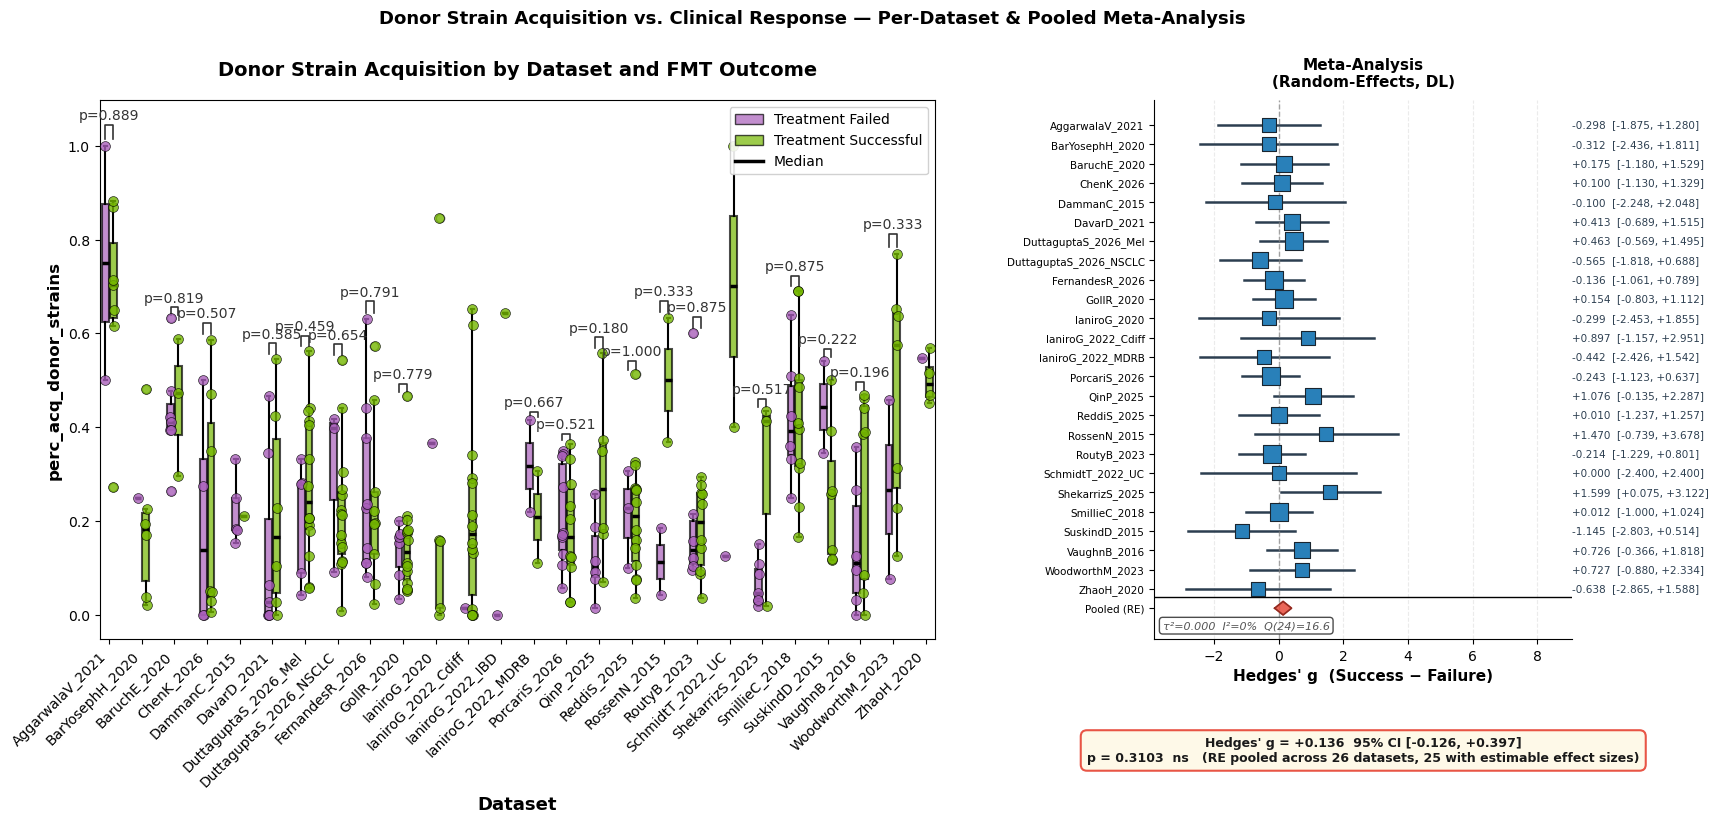

  Saved plots to /shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/figs/perc_acq_donor_strains_combined.png

STAT: perc_sgbs_lost

  Dataset                         n_succ  n_fail        U        p   sig
  ------------------------------------------------------------
  AggarwalaV_2021                      7       2      8.5   0.7598    ns
  BarYosephH_2020                      6       1        —        — insufficient
  BaruchE_2020                         3       7     12.0   0.8333    ns
  ChenK_2026                           7       4      6.0   0.1636    ns
  DammanC_2015                         1       5        —        — insufficient
  DavarD_2021                          6       7     13.0   0.2949    ns
  DuttaguptaS_2026_Mel                14       5     40.0   0.6868    ns
  DuttaguptaS_2026_NSCLC              15       3     10.0   0.1642    ns
  FernandesR_2026                      9       9     43.0   0.8598    ns
  GollR_2020                        

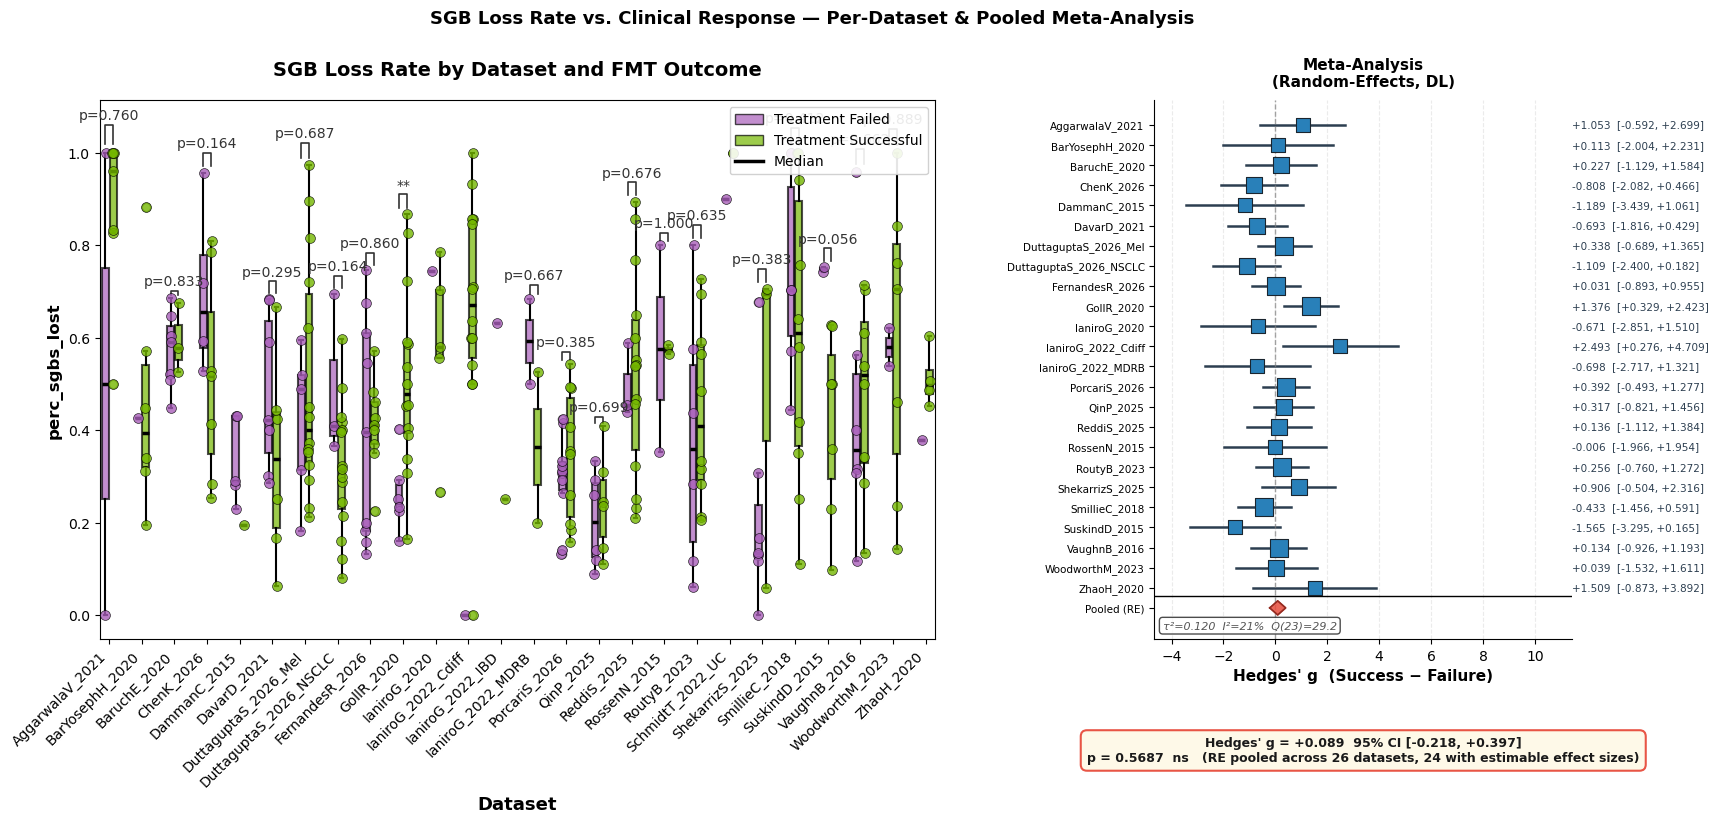

  Saved plots to /shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/figs/perc_sgbs_lost_combined.png

STAT: perc_strains_retained

  Dataset                         n_succ  n_fail        U        p   sig
  ------------------------------------------------------------
  AggarwalaV_2021                      7       2      9.0   0.5476    ns
  BarYosephH_2020                      6       1        —        — insufficient
  BaruchE_2020                         3       7      9.0   0.8175    ns
  ChenK_2026                           7       4     19.0   0.4121    ns
  DammanC_2015                         1       5        —        — insufficient
  DavarD_2021                          6       7     27.0   0.4308    ns
  DuttaguptaS_2026_Mel                14       5     30.0   0.6868    ns
  DuttaguptaS_2026_NSCLC              15       3     38.0   0.0760    ns
  FernandesR_2026                      9       9     38.0   0.8598    ns
  GollR_2020                         

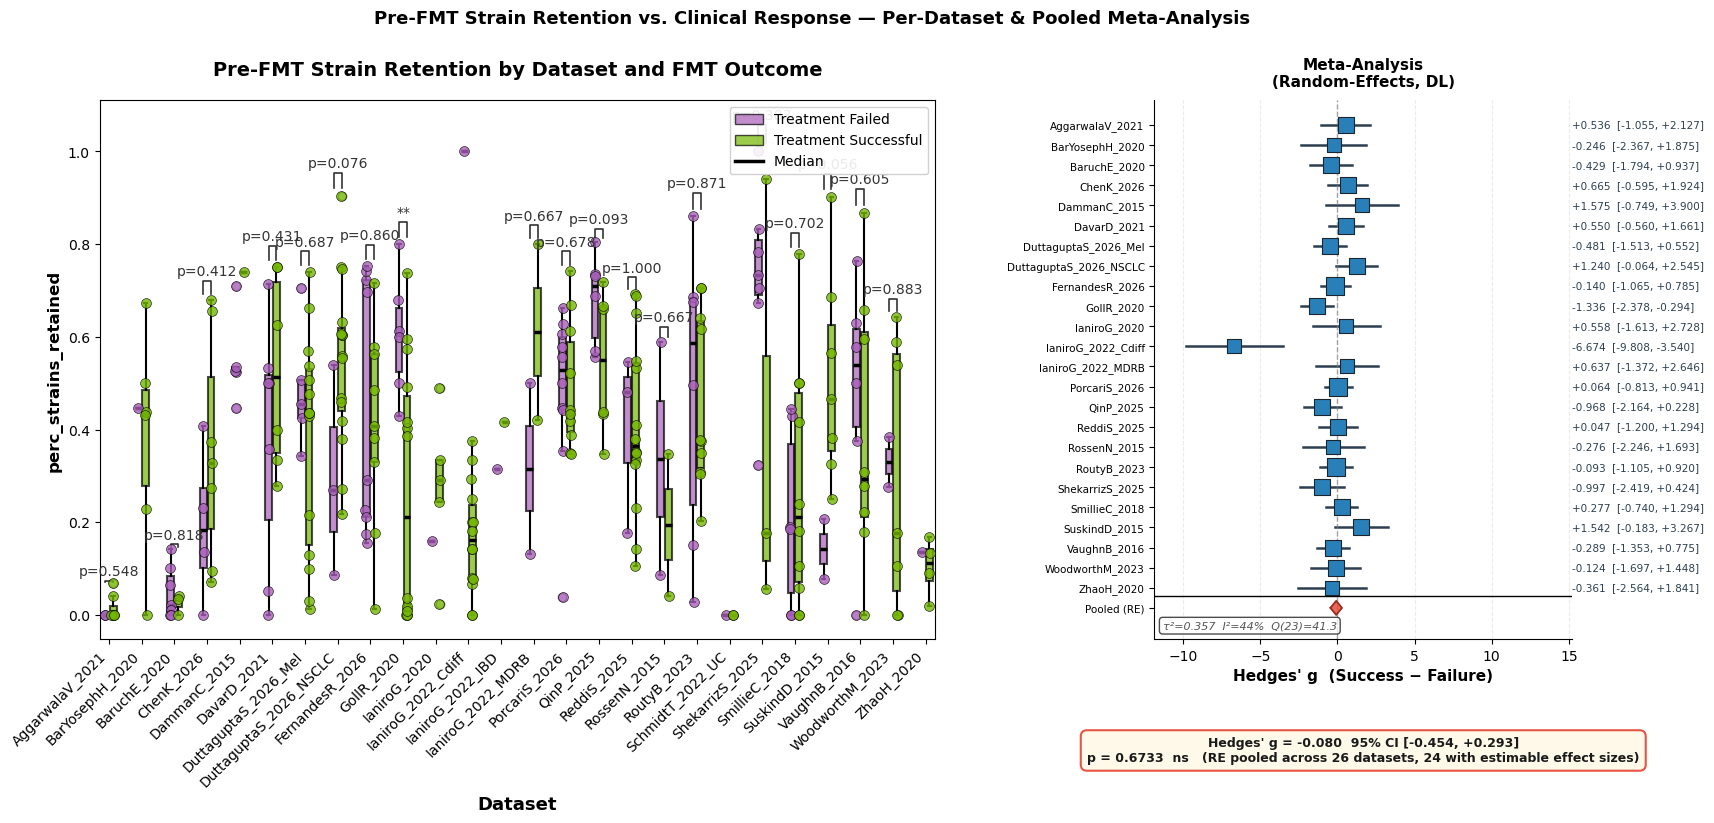

  Saved plots to /shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/figs/perc_strains_retained_combined.png

STAT: perc_strains_swapped

  Dataset                         n_succ  n_fail        U        p   sig
  ------------------------------------------------------------
  AggarwalaV_2021                      7       2      5.0   0.6305    ns
  BarYosephH_2020                      6       1        —        — insufficient
  BaruchE_2020                         3       7     12.0   0.8333    ns
  ChenK_2026                           7       4     18.0   0.5273    ns
  DammanC_2015                         1       5        —        — insufficient
  DavarD_2021                          6       7     23.0   0.8357    ns
  DuttaguptaS_2026_Mel                14       5     41.0   0.6216    ns
  DuttaguptaS_2026_NSCLC              15       3     14.0   0.3603    ns
  FernandesR_2026                      9       9     41.0   1.0000    ns
  GollR_2020                   

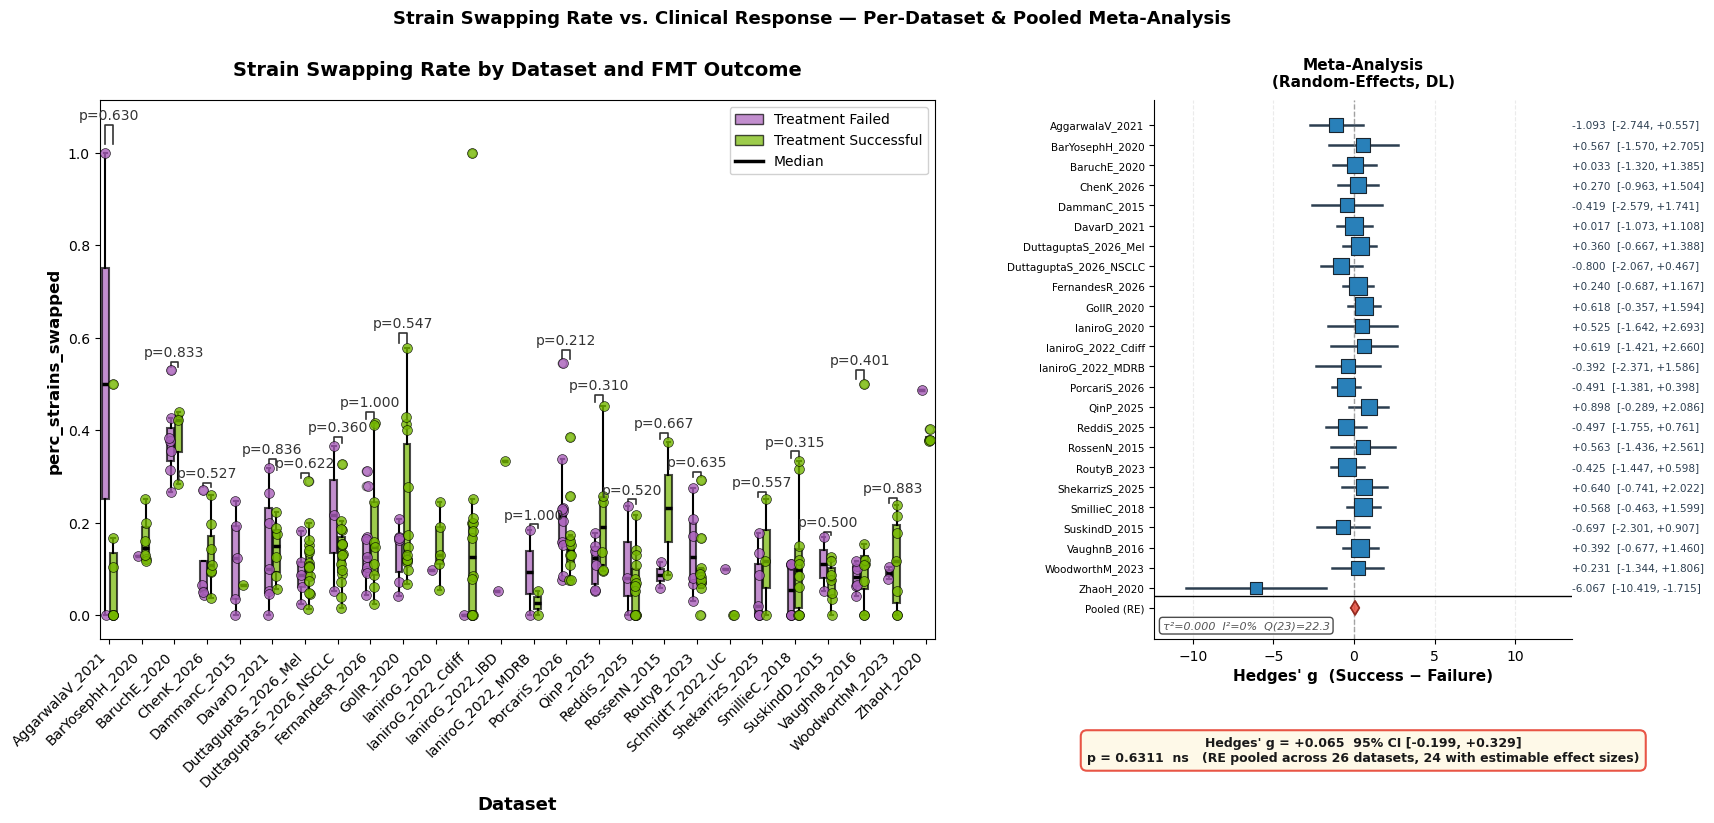

  Saved plots to /shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/figs/perc_strains_swapped_combined.png

STAT: perc_acq_other_strains

  Dataset                         n_succ  n_fail        U        p   sig
  ------------------------------------------------------------
  AggarwalaV_2021                      7       2      8.0   0.8889    ns
  BarYosephH_2020                      6       1        —        — insufficient
  BaruchE_2020                         3       7     10.0   1.0000    ns
  ChenK_2026                           7       4     17.0   0.6485    ns
  DammanC_2015                         1       5        —        — insufficient
  DavarD_2021                          6       7     15.0   0.4452    ns
  DuttaguptaS_2026_Mel                14       5     23.0   0.2976    ns
  DuttaguptaS_2026_NSCLC              15       3     27.0   0.6544    ns
  FernandesR_2026                      9       9     43.0   0.8598    ns
  GollR_2020                  

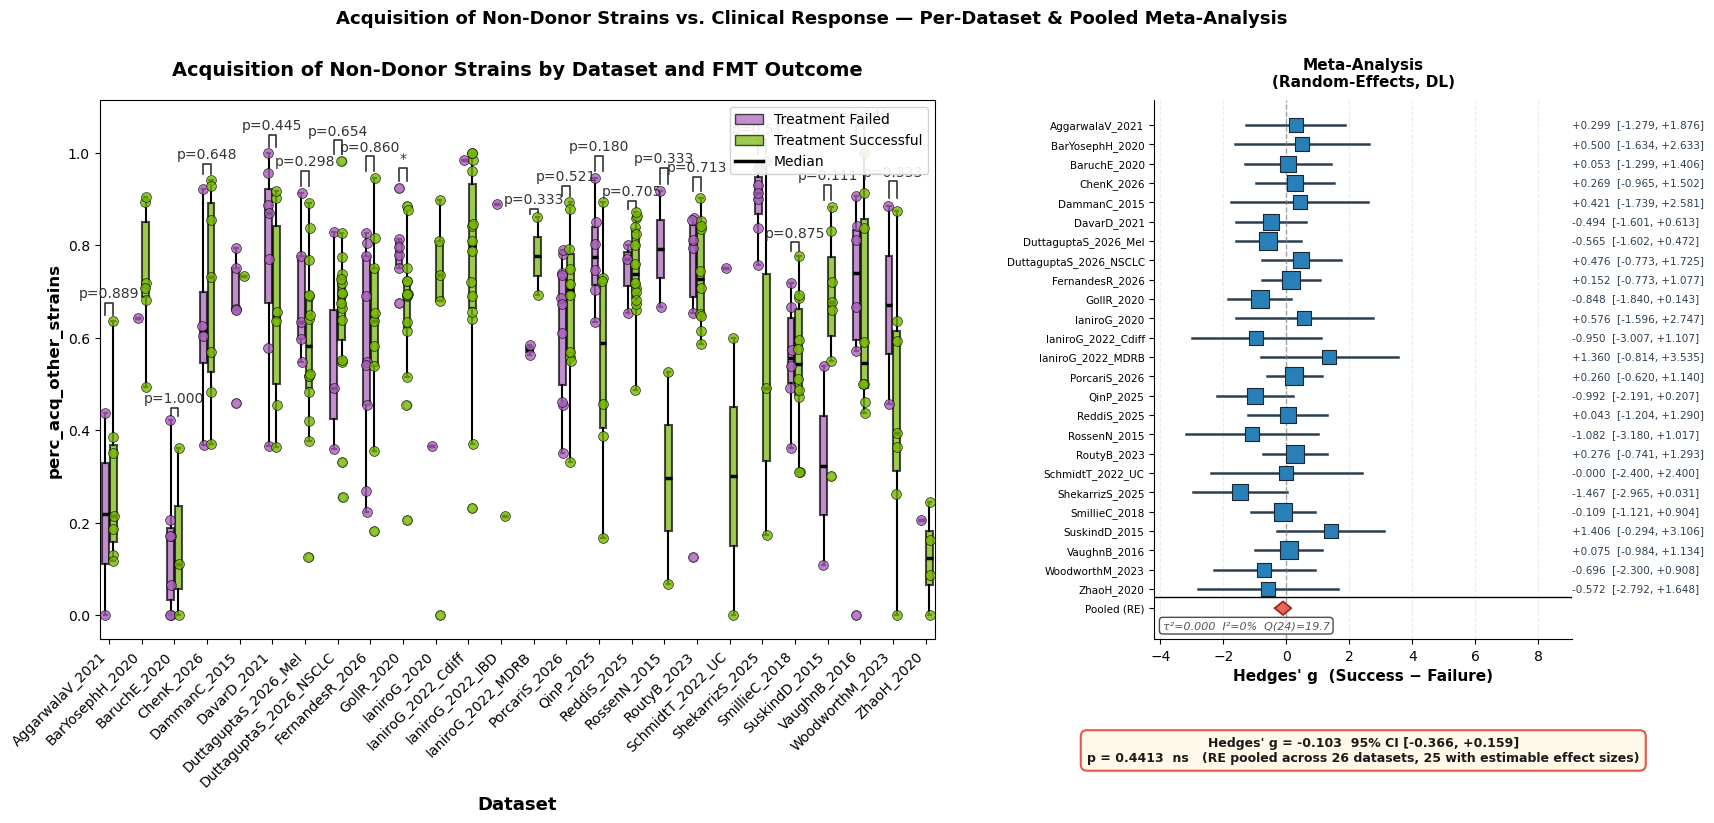

  Saved plots to /shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/figs/perc_acq_other_strains_combined.png

STAT: perc_strains_lost

  Dataset                         n_succ  n_fail        U        p   sig
  ------------------------------------------------------------
  AggarwalaV_2021                      7       2      5.0   0.5476    ns
  BarYosephH_2020                      6       1        —        — insufficient
  BaruchE_2020                         3       7     12.0   0.8175    ns
  ChenK_2026                           7       4      9.0   0.4121    ns
  DammanC_2015                         1       5        —        — insufficient
  DavarD_2021                          6       7     15.0   0.4308    ns
  DuttaguptaS_2026_Mel                14       5     40.0   0.6868    ns
  DuttaguptaS_2026_NSCLC              15       3      7.0   0.0760    ns
  FernandesR_2026                      9       9     43.0   0.8598    ns
  GollR_2020                     

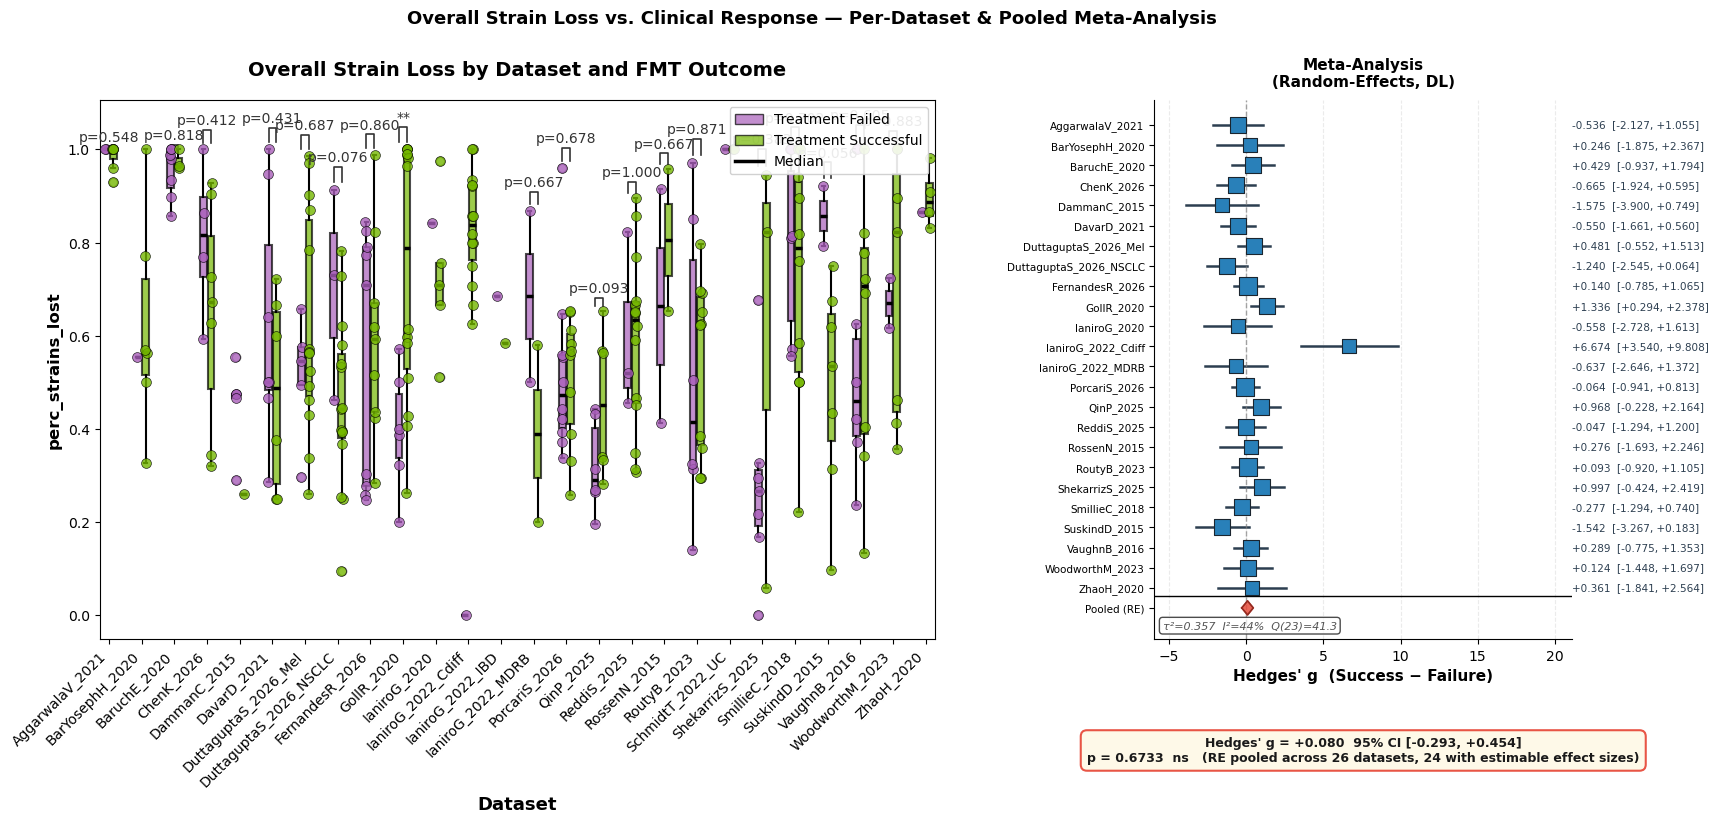

  Saved plots to /shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/figs/perc_strains_lost_combined.png

STAT: doser

  Dataset                         n_succ  n_fail        U        p   sig
  ------------------------------------------------------------
  AggarwalaV_2021                      7       2     12.0   0.2222    ns
  BarYosephH_2020                      6       1        —        — insufficient
  BaruchE_2020                         3       7     18.0   0.1084    ns
  ChenK_2026                           7       4     18.0   0.5064    ns
  DammanC_2015                         1       5        —        — insufficient
  DavarD_2021                          6       7     23.0   0.8255    ns
  DuttaguptaS_2026_Mel                14       5     46.0   0.3306    ns
  DuttaguptaS_2026_NSCLC              15       3     24.0   0.9118    ns
  FernandesR_2026                      9       9     47.0   0.5962    ns
  GollR_2020                          14       6  

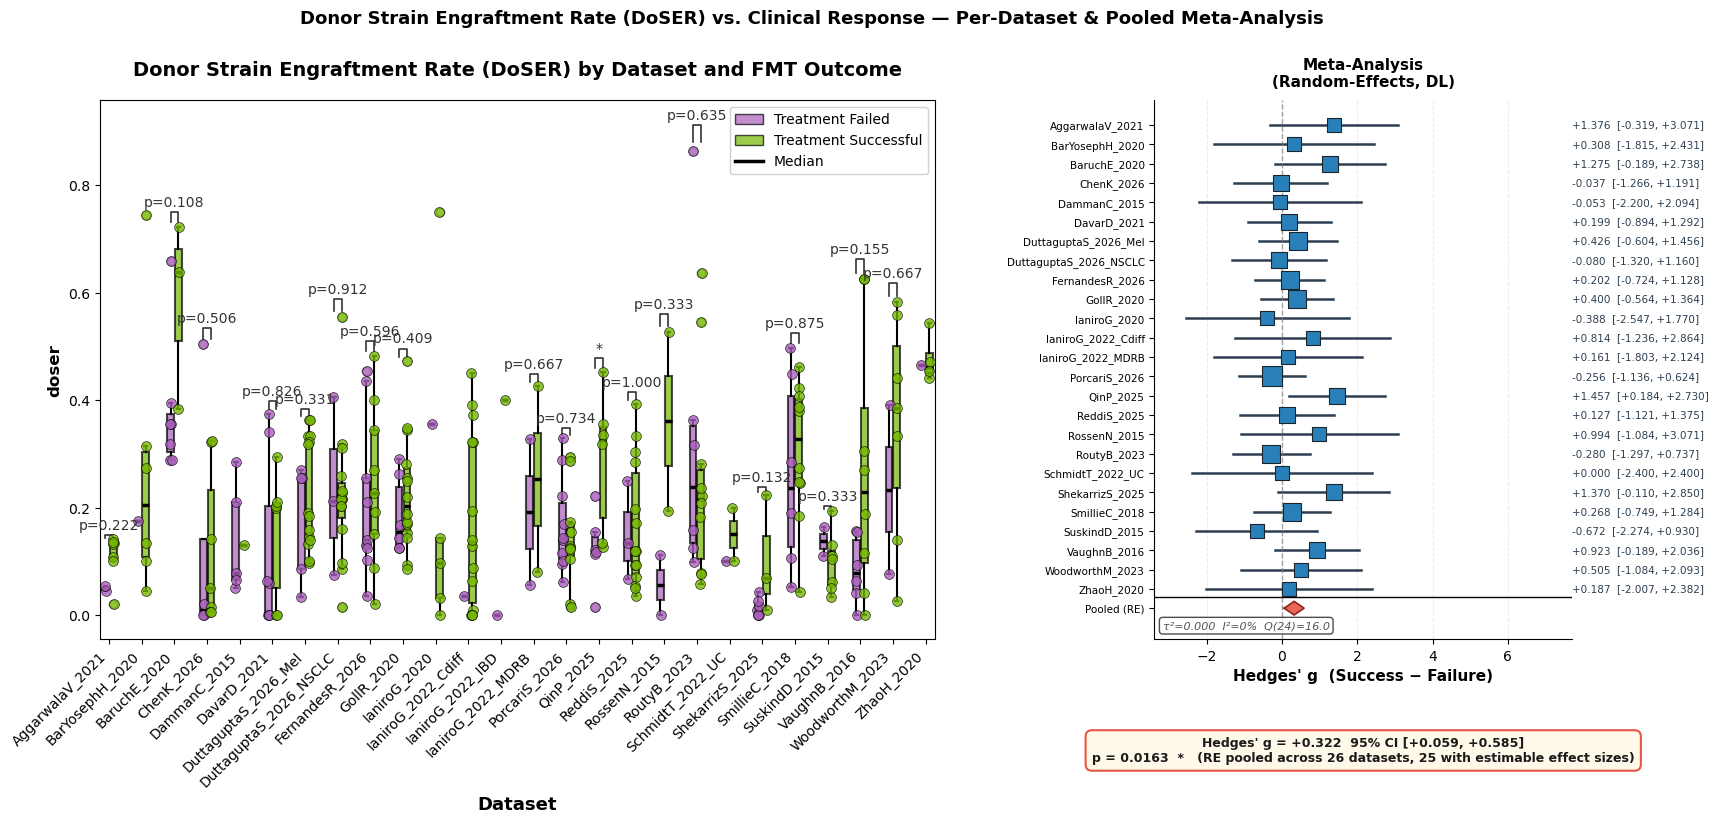

  Saved plots to /shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/figs/doser_combined.png

SUMMARY: Pooled RE Hedges' g across all stats
  Stat                              g_re                 95% CI          p     I²   sig
  ---------------------------------------------------------------------------
  perc_acq_donor_strains          +0.136       [-0.126, +0.397]     0.3103     0%    ns
  perc_sgbs_lost                  +0.089       [-0.218, +0.397]     0.5687    21%    ns
  perc_strains_retained           -0.080       [-0.454, +0.293]     0.6733    44%    ns
  perc_strains_swapped            +0.065       [-0.199, +0.329]     0.6311     0%    ns
  perc_acq_other_strains          -0.103       [-0.366, +0.159]     0.4413     0%    ns
  perc_strains_lost               +0.080       [-0.293, +0.454]     0.6733    44%    ns
  doser                           +0.322       [+0.059, +0.585]     0.0163     0%     *


In [7]:
def plot_combined(stat, stat_data, stat_datasets, mw_results, res, save_path):
    """Boxplot (left) + forest plot (right) for one stat."""
    meta_df = res['meta_df']
    g_re, ci_lo_re, ci_hi_re, p_re = res['g_re'], res['ci_lo_re'], res['ci_hi_re'], res['p_re']
    tau2, Q, df_Q, I2, k = res['tau2'], res['Q'], res['df_Q'], res['I2'], res['k']

    colors = {True: COLOR_SUCCESS, False: COLOR_FAILURE}

    fig = plt.figure(figsize=(19, 7))
    gs  = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.35)
    ax_box    = fig.add_subplot(gs[0])
    ax_forest = fig.add_subplot(gs[1])

    positions, box_data, box_colors = [], [], []
    tick_positions, tick_labels     = [], []
    pos = 0
    BOX_SP, DATASET_GAP = 0.7, 1.5

    for dataset in stat_datasets:
        d_data = stat_data[stat_data['dataset'] == dataset]
        dataset_start = pos
        for success_val in [False, True]:
            sd = d_data[d_data['success'] == success_val][stat].values
            if len(sd) > 0:
                box_data.append(sd)
                positions.append(pos)
                box_colors.append(colors[success_val])
                pos += BOX_SP
        if pos > dataset_start:
            tick_positions.append((dataset_start + pos - BOX_SP) / 2)
            tick_labels.append(dataset)
        pos += DATASET_GAP

    if box_data:
        bp = ax_box.boxplot(
            box_data, positions=positions, widths=0.6, patch_artist=True,
            showmeans=False, whis=1.5,
            boxprops=dict(linewidth=1.5),
            medianprops=dict(color='black', linewidth=2.5),
            whiskerprops=dict(linewidth=1.5),
            capprops=dict(linewidth=1.5),
            flierprops=dict(marker='o', markersize=6, alpha=0.5)
        )
        for patch, color in zip(bp['boxes'], box_colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)

        for data, pos_x, color in zip(box_data, positions, box_colors):
            x_jitter = np.random.normal(0, 0.04, size=len(data))
            ax_box.scatter(
                np.full(len(data), pos_x) + x_jitter, data,
                color=color, s=50, alpha=0.8, zorder=3,
                edgecolors='black', linewidth=0.5
            )

        # Annotate Mann-Whitney p-values
        ann_pos = 0
        for dataset in stat_datasets:
            d_data   = stat_data[stat_data['dataset'] == dataset]
            pair_pos = []
            for success_val in [False, True]:
                sd = d_data[d_data['success'] == success_val][stat].values
                if len(sd) > 0:
                    pair_pos.append(ann_pos)
                    ann_pos += BOX_SP
            ann_pos += DATASET_GAP

            if len(pair_pos) == 2 and dataset in mw_results and not np.isnan(mw_results[dataset]['p']):
                p   = mw_results[dataset]['p']
                sig = sig_stars(p, ns=f"p={p:.3f}")
                x_mid  = np.mean(pair_pos)
                y_vals = d_data[stat]
                y_top  = y_vals.max() + 0.02 * (y_vals.max() - y_vals.min() + 0.01)
                y_bar  = y_top + 0.04 * (y_vals.max() - y_vals.min() + 0.01)
                ax_box.plot([pair_pos[0], pair_pos[0], pair_pos[1], pair_pos[1]],
                            [y_top, y_bar, y_bar, y_top], lw=1.2, color='#333333')
                ax_box.text(x_mid, y_bar + 0.005, sig,
                            ha='center', va='bottom', fontsize=10, color='#333333')

    plot_title = STAT_TITLES.get(stat, stat)
    ax_box.set_ylabel(stat, fontsize=12, fontweight='bold')
    ax_box.set_xlabel('Dataset', fontsize=13, fontweight='bold')
    ax_box.set_title(f'{plot_title} by Dataset and FMT Outcome', fontsize=14, fontweight='bold', pad=18)
    ax_box.set_xticks(tick_positions)
    ax_box.set_xticklabels(tick_labels, fontsize=10, rotation=45, ha='right')

    legend_elements = [
        Patch(facecolor=colors[False], alpha=0.7, label='Treatment Failed',    edgecolor='black'),
        Patch(facecolor=colors[True],  alpha=0.7, label='Treatment Successful', edgecolor='black'),
        plt.Line2D([0], [0], color='black', linewidth=2.5, label='Median')
    ]
    ax_box.legend(handles=legend_elements, loc='upper right', fontsize=10, framealpha=0.9)

    # Forest plot
    if len(meta_df) >= 1:
        n_studies   = len(meta_df)
        y_positions = list(range(n_studies, 0, -1))
        y_pooled    = 0

        for i, (_, row) in enumerate(meta_df.iterrows()):
            y = y_positions[i]
            ax_forest.plot([row['ci_lo'], row['ci_hi']], [y, y], color='#2c3e50', lw=1.8, zorder=2)
            sq_size = 80 + row['pct_weight'] * 12
            ax_forest.scatter(row['g'], y, marker='s', s=sq_size, color='#2980b9',
                              edgecolors='#1a252f', linewidth=0.8, zorder=3)

        if not np.isnan(g_re):
            diamond_x = [ci_lo_re, g_re, ci_hi_re, g_re]
            diamond_y = [y_pooled, y_pooled + 0.35, y_pooled, y_pooled - 0.35]
            ax_forest.fill(diamond_x, diamond_y, color='#e74c3c', zorder=3, alpha=0.85)
            ax_forest.plot(diamond_x + [diamond_x[0]], diamond_y + [diamond_y[0]],
                           color='#922b21', lw=1.2, zorder=4)

        ax_forest.axvline(0, color='grey', lw=1, linestyle='--', alpha=0.7)

        y_labels = list(meta_df['dataset']) + ['Pooled (RE)']
        ax_forest.set_yticks(list(y_positions) + [y_pooled])
        ax_forest.set_yticklabels(y_labels, fontsize=7.5)
        ax_forest.axhline(0.6, color='black', lw=1.0)
        ax_forest.set_xlabel("Hedges' g  (Success − Failure)", fontsize=11, fontweight='bold')
        ax_forest.set_title("Meta-Analysis\n(Random-Effects, DL)", fontsize=11, fontweight='bold', pad=10)

        all_ci = list(meta_df['ci_lo']) + list(meta_df['ci_hi'])
        if not np.isnan(g_re):
            all_ci += [ci_lo_re, ci_hi_re]
        x_pad = (max(all_ci) - min(all_ci)) * 0.15
        ax_forest.set_xlim(min(all_ci) - x_pad, max(all_ci) + x_pad * 5.5)

        for i, (_, row) in enumerate(meta_df.iterrows()):
            ax_forest.text(ax_forest.get_xlim()[1], y_positions[i],
                           f"{row['g']:+.3f}  [{row['ci_lo']:+.3f}, {row['ci_hi']:+.3f}]",
                           va='center', ha='left', fontsize=7.5, color='#2c3e50')

        if not np.isnan(I2):
            het_str = f"τ²={tau2:.3f}  I²={I2:.0f}%  Q({df_Q})={Q:.1f}"
            ax_forest.text(0.02, 0.02, het_str, transform=ax_forest.transAxes, fontsize=8,
                           color='#555', style='italic',
                           bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

        ax_forest.yaxis.grid(False)
        ax_forest.xaxis.grid(True, alpha=0.25, linestyle='--')
        ax_forest.spines['top'].set_visible(False)
        ax_forest.spines['right'].set_visible(False)

    plt.suptitle(f'{plot_title} vs. Clinical Response — Per-Dataset & Pooled Meta-Analysis',
                 fontsize=13, fontweight='bold', y=1.01)

    if not np.isnan(g_re):
        main_finding = (
            f"Hedges' g = {g_re:+.3f}  95% CI [{ci_lo_re:+.3f}, {ci_hi_re:+.3f}]\n"
            f"{fmt_p(p_re, sep=' ')}  {sig_stars(p_re)}   "
            f"(RE pooled across {len(stat_datasets)} datasets, {k} with estimable effect sizes)"
        )
        ax_forest.text(
            0.5, -0.18, main_finding, transform=ax_forest.transAxes,
            fontsize=9, ha='center', va='top', color='#1a1a1a', fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#fef9e7',
                      edgecolor='#e74c3c', linewidth=1.5, alpha=0.95)
        )

    fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"  Saved plots to {save_path}")


# ── Run for every stat on the heterogeneous full cohort ──────────────────────
plot_data = filter_heterogeneous(fmt_merged)
print(f"Datasets with heterogeneous success values: {sorted(plot_data['dataset'].unique())}")
print(plot_data['success'].value_counts(dropna=False))

all_meta_results = {}
for stat in stats_to_test:
    stat_data = plot_data.dropna(subset=[stat])
    if stat_data.empty:
        print(f"\nSkipping {stat}: no data")
        continue

    print("\n" + "=" * 70 + f"\nSTAT: {stat}\n" + "=" * 70)
    stat_datasets = sorted(stat_data['dataset'].unique())

    mw_results = mann_whitney_by_dataset(stat_data, stat, stat_datasets, verbose=True)
    res = meta_analyze(stat_data, stat, verbose=True)
    print_meta(res)

    all_meta_results[stat] = {**res, 'mw_results': mw_results}
    plot_combined(stat, stat_data, stat_datasets, mw_results, res,
                  save_path=os.path.join(SAVE_DIR, f'{stat}_combined.png'))

# ── Summary across all stats ─────────────────────────────────────────────────
print("\n" + "=" * 70 + "\nSUMMARY: Pooled RE Hedges' g across all stats\n" + "=" * 70)
print(f"  {'Stat':<30} {'g_re':>7} {'95% CI':>22} {'p':>10} {'I²':>6} {'sig':>5}")
print("  " + "-" * 75)
for s, r in all_meta_results.items():
    if np.isnan(r['g_re']):
        print(f"  {s:<30} {'—':>7} {'—':>22} {'—':>10} {'—':>6} {'—':>5}")
        continue
    ci = f"[{r['ci_lo_re']:+.3f}, {r['ci_hi_re']:+.3f}]"
    print(f"  {s:<30} {r['g_re']:>+7.3f} {ci:>22} {fmt_p(r['p_re'], label=False):>10} {r['I2']:>5.0f}% {sig_stars(r['p_re']):>5}")

## 4. B — DoSER: boxplots, forest plots, summary table

In [8]:
# ── Pooled results for EVERY stat × (full / cancer / non-cancer) — reused by B and C ──
full_df      = filter_heterogeneous(fmt_merged)
cancer_df    = filter_heterogeneous(fmt_merged[fmt_merged['indication'] == 'Cancer'])
noncancer_df = filter_heterogeneous(fmt_merged[fmt_merged['indication'] != 'Cancer'])

stat_group_results = {}
for s in stats_to_test:
    stat_group_results[s] = {
        'full':      summarize_group(full_df,      f"FULL COHORT [{s}]", s),
        'cancer':    summarize_group(cancer_df,    f"CANCER [{s}]",      s),
        'noncancer': summarize_group(noncancer_df, f"NON-CANCER [{s}]",  s),
    }

stat = 'doser'
full_result      = stat_group_results[stat]['full']
cancer_result    = stat_group_results[stat]['cancer']
noncancer_result = stat_group_results[stat]['noncancer']

summary_rows = [
    to_summary_row('Full cohort', full_result),
    to_summary_row('Cancer only', cancer_result),
    to_summary_row('Non-cancer',  noncancer_result),
]


FULL COHORT [perc_acq_donor_strains] — perc_acq_donor_strains meta-analysis (k=25 datasets)

  Dataset                         g                 95% CI        p  Weight%
  ------------------------------------------------------------------------
  AggarwalaV_2021            -0.298       [-1.875, +1.280]   0.7115     2.8%
  BarYosephH_2020            -0.312       [-2.436, +1.811]   0.7731     1.5%
  BaruchE_2020               +0.175       [-1.180, +1.529]   0.8004     3.7%
  ChenK_2026                 +0.100       [-1.130, +1.329]   0.8737     4.5%
  DammanC_2015               -0.100       [-2.248, +2.048]   0.9273     1.5%
  DavarD_2021                +0.413       [-0.689, +1.515]   0.4626     5.6%
  DuttaguptaS_2026_Mel       +0.463       [-0.569, +1.495]   0.3789     6.4%
  DuttaguptaS_2026_NSCLC     -0.565       [-1.818, +0.688]   0.3768     4.4%
  FernandesR_2026            -0.136       [-1.061, +0.789]   0.7729     8.0%
  GollR_2020                 +0.154       [-0.803, +1.112]   

In [9]:
import pandas as pd
import numpy as np

group_names = {'full': 'Full cohort', 'cancer': 'Cancer only', 'noncancer': 'Non-cancer'}
pooled_cols = ['g_re', 'ci_lo_re', 'ci_hi_re', 'p_re', 'tau2', 'Q', 'df_Q', 'p_Q', 'I2']

dataset_rows, pooled_rows = [], []
for s in stats_to_test:
    for grp, label in group_names.items():
        res = stat_group_results[s][grp]
        k   = res['k']

        # ── per-dataset Hedges' g rows ──
        md = res['meta_df']
        if len(md):
            d = md.copy()
            d.insert(0, 'stat', s)
            d.insert(1, 'subgroup', label)
            d.insert(2, 'row_type', 'dataset')
            d.insert(3, 'indication', d['dataset'].map(dataset_indication))
            dataset_rows.append(d)

        # ── pooled random-effects row ──
        prow = {'stat': s, 'subgroup': label, 'row_type': 'pooled',
                'dataset': 'POOLED (RE)', 'k': k,
                'n_succ': md['n_succ'].sum() if len(md) else np.nan,
                'n_fail': md['n_fail'].sum() if len(md) else np.nan}
        prow.update({c: res[c] for c in pooled_cols})
        pooled_rows.append(prow)

all_results = pd.concat(dataset_rows + [pd.DataFrame(pooled_rows)],
                        ignore_index=True, sort=False)

# Pooled-level columns are blank on dataset rows; keep per-dataset g/CI/p in their own columns
all_results = all_results.rename(columns={
    'g': 'hedges_g', 'se_g': 'se', 'ci_lo': 'ci_lo', 'ci_hi': 'ci_hi', 'p_val': 'p',
    'w_re': 'weight_re', 'pct_weight': 'pct_weight_re',
})

front = ['stat', 'subgroup', 'row_type', 'dataset', 'indication', 'k',
         'n_succ', 'n_fail', 'mean_succ', 'mean_fail',
         'hedges_g', 'var_g', 'se', 'ci_lo', 'ci_hi', 'p',
         'weight_fe', 'var_re', 'weight_re', 'pct_weight_re',
         'g_re', 'ci_lo_re', 'ci_hi_re', 'p_re', 'tau2', 'Q', 'df_Q', 'p_Q', 'I2']
all_results = all_results[[c for c in front if c in all_results.columns]]

# Order: stat, subgroup (full, cancer, non-cancer), datasets then pooled row
grp_order = {v: i for i, v in enumerate(group_names.values())}
all_results['_g'] = all_results['subgroup'].map(grp_order)
all_results['_t'] = all_results['row_type'].map({'dataset': 0, 'pooled': 1})
all_results['_s'] = all_results['stat'].map({s: i for i, s in enumerate(stats_to_test)})
all_results = (all_results.sort_values(['_s', '_g', '_t', 'dataset'], kind='stable')
                          .drop(columns=['_s', '_g', '_t']))

all_results.to_csv('meta_analysis_all_results.csv', index=False)
print(f"Saved {len(all_results)} rows "
      f"({(all_results.row_type == 'pooled').sum()} pooled, "
      f"{(all_results.row_type == 'dataset').sum()} dataset-level) "
      f"to 'meta_analysis_all_results.csv'")

Saved 363 rows (21 pooled, 342 dataset-level) to 'meta_analysis_all_results.csv'


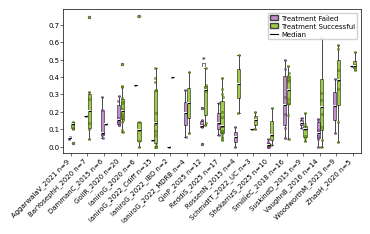

  Saved boxplot to /shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/doser_boxplot_noncancer.svg


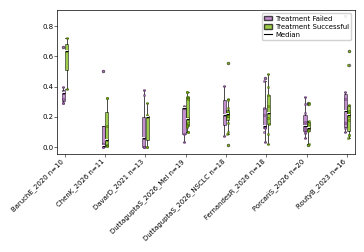

  Saved boxplot to /shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/doser_boxplot_cancer.svg


In [10]:
# ══════════════════════════════════════════════════════════════════════════
# BOXPLOT — condensed 85 x 50 mm, Arial 5 pt, no axis labels/title, 1-line ticks
# ══════════════════════════════════════════════════════════════════════════
MM = 1 / 25.4

BOX_W_MM, BOX_H_MM = 85, 50
BOX_FIGSIZE   = (BOX_W_MM * MM, BOX_H_MM * MM)
BOX_FONT_SIZE = 5

# margins in mm: left, bottom, right, top (raise _B if rotated labels get clipped)
_L, _B, _R, _T = 8, 12, 1.5, 1.5
SHARED_AXES_RECT = (_L / BOX_W_MM,
                    _B / BOX_H_MM,
                    1 - _R / BOX_W_MM,
                    1 - _T / BOX_H_MM)   # (left, bottom, right, top)

BOX_RC = {
    'font.size':          5,
    'axes.labelsize':     5,
    'xtick.labelsize':    5,
    'ytick.labelsize':    5,
    'legend.fontsize':    5,
    'axes.linewidth':     0.5,
    'xtick.major.width':  0.4,
    'ytick.major.width':  0.4,
    'xtick.major.size':   2,
    'ytick.major.size':   2,
    'xtick.major.pad':    1,
    'ytick.major.pad':    1,
    'svg.fonttype':       'none',   # keep text as real 5 pt text in the SVG
}


def plot_boxplot_only(stat, stat_data, stat_datasets, mw_results, save_path,
                      figsize=BOX_FIGSIZE, dataset_gap=DATASET_GAP_DEFAULT,
                      xlim=None, axes_rect=SHARED_AXES_RECT):
    colors = {True: COLOR_SUCCESS, False: COLOR_FAILURE}
    FS = BOX_FONT_SIZE

    with mpl.rc_context(BOX_RC):
        fig, ax_box = plt.subplots(figsize=figsize)

        # Layout: one entry per dataset → [(success_val, x, values), ...]
        layout, pos = [], 0
        for dataset in stat_datasets:
            d_data = stat_data[stat_data['dataset'] == dataset]
            items = []
            for success_val in [False, True]:
                vals = d_data[d_data['success'] == success_val][stat].values
                if len(vals) > 0:
                    items.append((success_val, pos, vals))
                    pos += BOX_SPACING
            if items:
                layout.append((dataset, d_data, items))
            pos += dataset_gap

        if layout:
            flat = [it for _, _, items in layout for it in items]
            box_data   = [vals for _, _, vals in flat]
            positions  = [x for _, x, _ in flat]
            box_colors = [colors[sv] for sv, _, _ in flat]

            bp = ax_box.boxplot(
                box_data, positions=positions,
                widths=0.9 * BOX_SPACING,       # was 0.7; scales with the spacing so neighbours don't overlap
                capwidths=0.6 * BOX_SPACING,    # whisker caps, default is half the box width
                patch_artist=True,
                showmeans=False, whis=1.5,
                boxprops=dict(linewidth=0.5),
                medianprops=dict(color='black', linewidth=0.8, zorder=5),
                whiskerprops=dict(linewidth=0.5),
                capprops=dict(linewidth=0.5),
                flierprops=dict(marker='o', markersize=1.5, alpha=0.5)
            )
            for patch, color in zip(bp['boxes'], box_colors):
                patch.set_facecolor(color)
                patch.set_alpha(0.7)

            # Medians above the scatter dots, with a white halo for legibility
            for median in bp['medians']:
                median.set_zorder(5)
                median.set_path_effects([
                    pe.Stroke(linewidth=median.get_linewidth() + 0.6, foreground='white'),
                    pe.Normal()
                ])

            for vals, x, color in zip(box_data, positions, box_colors):
                ax_box.scatter(np.full(len(vals), x) + np.random.normal(0, 0.05, size=len(vals)), vals,
                               color=color, s=3, alpha=0.8, zorder=3, edgecolors='black', linewidth=0.2)

            # Significance brackets (p < 0.05 only)
            for dataset, d_data, items in layout:
                p = mw_results.get(dataset, {}).get('p', np.nan)
                if len(items) != 2 or np.isnan(p) or p >= 0.05:
                    continue
                y_vals = d_data[stat]
                span   = y_vals.max() - y_vals.min() + 0.01
                y_top  = y_vals.max() + 0.02 * span
                y_bar  = y_top + 0.04 * span
                x0, x1 = items[0][1], items[1][1]
                ax_box.plot([x0, x0, x1, x1], [y_top, y_bar, y_bar, y_top], lw=0.5, color='#333333')
                ax_box.text((x0 + x1) / 2, y_bar + 0.005, sig_stars(p), ha='center', va='bottom',
                            fontsize=FS, fontweight='bold', color='#333333')

            ax_box.set_xticks([np.mean([x for _, x, _ in items]) for _, _, items in layout])
            ax_box.set_xticklabels([f'{ds} n={d[stat].notna().sum()}' for ds, d, _ in layout],
                                   fontsize=FS, rotation=45, ha='right')

        ax_box.set_xlabel(''); ax_box.set_ylabel(''); ax_box.set_title('')
        ax_box.tick_params(axis='both', labelsize=FS)
        if xlim is not None:
            ax_box.set_xlim(*xlim)

        legend_elements = [
            Patch(facecolor=colors[False], alpha=0.7, label='Treatment Failed',     edgecolor='black'),
            Patch(facecolor=colors[True],  alpha=0.7, label='Treatment Successful', edgecolor='black'),
            plt.Line2D([0], [0], color='black', linewidth=0.8, label='Median'),
        ]
        ax_box.legend(handles=legend_elements, loc='upper right', fontsize=FS, framealpha=0.9,
                      handlelength=1.2, labelspacing=0.3, borderpad=0.3, handletextpad=0.4)

        # Fixed rect instead of tight_layout → identical plot area (and box widths) across panels
        left, bottom, right, top = axes_rect
        fig.subplots_adjust(left=left, bottom=bottom, right=right, top=top)

        fig.savefig(save_path, format='svg', bbox_inches=None, pad_inches=0)
        plt.show()
    print(f"  Saved boxplot to {save_path}")


def _last_box_position(stat_datasets, stat_data, stat, box_spacing, dataset_gap):
    n_boxes, n_datasets_with_data = 0, 0
    for dataset in stat_datasets:
        d_data = stat_data[stat_data['dataset'] == dataset]
        c = sum(len(d_data[d_data['success'] == sv][stat].values) > 0 for sv in [False, True])
        if c > 0:
            n_boxes += c
            n_datasets_with_data += 1
    if n_boxes == 0:
        return 0.0, 0, 0
    return box_spacing * (n_boxes - 1) + dataset_gap * max(n_datasets_with_data - 1, 0), n_boxes, n_datasets_with_data


def solve_matched_gap(stat_datasets, stat_data, stat, box_spacing, target_last_pos):
    """Dataset gap that makes this panel span exactly target_last_pos on the x-axis."""
    _, n_boxes, n_datasets = _last_box_position(stat_datasets, stat_data, stat, box_spacing, DATASET_GAP_DEFAULT)
    if n_datasets <= 1:
        return DATASET_GAP_DEFAULT
    return max((target_last_pos - box_spacing * (n_boxes - 1)) / (n_datasets - 1), box_spacing)


def plot_matched_boxplots(stat, noncancer_df, cancer_df, out_dir=OUT_DIR):
    """Non-cancer and cancer boxplots with matched x-span so box widths are identical."""
    panels = {}
    for name, df in [('noncancer', noncancer_df), ('cancer', cancer_df)]:
        sd = df.dropna(subset=[stat])
        dsets = sorted(sd['dataset'].unique())
        panels[name] = (sd, dsets, mann_whitney_by_dataset(sd, stat, dsets))

    target = max(_last_box_position(dsets, sd, stat, BOX_SPACING, DATASET_GAP_DEFAULT)[0]
                 for sd, dsets, _ in panels.values())
    xlim = (-1.5, target + 1.5)

    for name, (sd, dsets, mw) in panels.items():
        gap = solve_matched_gap(dsets, sd, stat, BOX_SPACING, target)
        plot_boxplot_only(stat, sd, dsets, mw,
                          save_path=os.path.join(out_dir, f'{stat}_boxplot_{name}.svg'),
                          dataset_gap=gap, xlim=xlim)


plot_matched_boxplots(stat, noncancer_df, cancer_df)

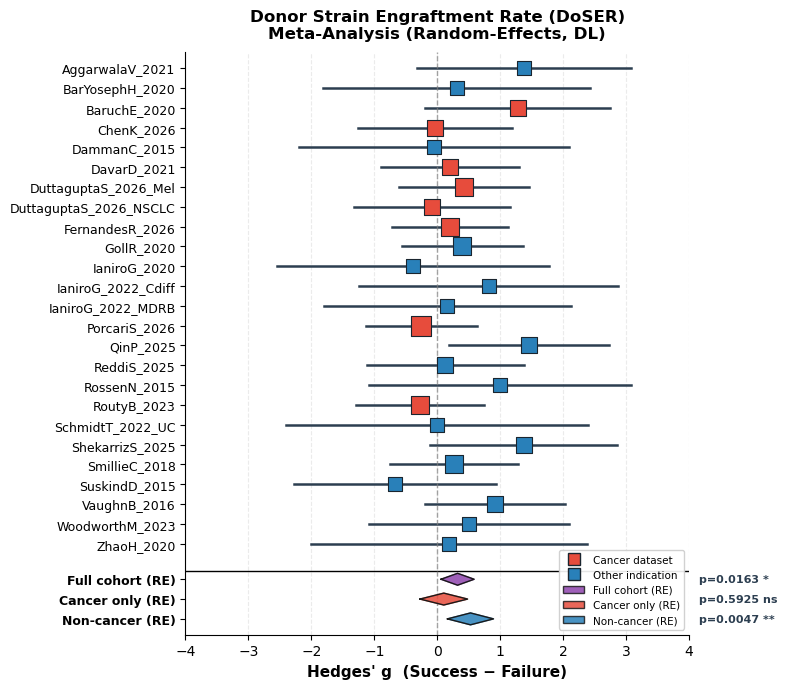

  Saved forest plot to /shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/doser_forest_all_groups.svg


In [11]:
# ══════════════════════════════════════════════════════════════════════════
# FOREST PLOT — cancer datasets red, three pooled diamonds, p-value only
# ══════════════════════════════════════════════════════════════════════════
def _draw_diamond(ax, y, g_re, ci_lo_re, ci_hi_re, p_re, color, trans, half_h=0.3, fontsize=7):
    if np.isnan(g_re):
        ax.text(1.02, y, "p=—", transform=trans, va='center', ha='left',
                fontsize=fontsize, fontweight='bold', color='#2c3e50', clip_on=False)
        return
    diamond_x = [ci_lo_re, g_re, ci_hi_re, g_re]
    diamond_y = [y, y + half_h, y, y - half_h]
    ax.fill(diamond_x, diamond_y, color=color, zorder=3, alpha=0.85)
    ax.plot(diamond_x + [diamond_x[0]], diamond_y + [diamond_y[0]], color='#1a1a1a', lw=1.0, zorder=4)
    label_text = f"{fmt_p(p_re)} {sig_stars(p_re)}" if not np.isnan(p_re) else "p=—"
    ax.text(1.02, y, label_text, transform=trans, va='center', ha='left',
            fontsize=fontsize, fontweight='bold', color='#2c3e50', clip_on=False)


def plot_forest_only(stat, meta_df, pooled_groups, save_path):
    fig, ax_forest = plt.subplots(figsize=FOREST_FIGSIZE)

    if len(meta_df) >= 1:
        n_studies = len(meta_df)
        study_y_positions = list(range(n_studies, 0, -1))
        gap = 0.8
        diamond_y_positions = [-gap - i for i in range(len(pooled_groups))]
        trans = transforms.blended_transform_factory(ax_forest.transAxes, ax_forest.transData)

        for i, (_, row) in enumerate(meta_df.iterrows()):
            y = study_y_positions[i]
            dataset_color = CANCER_COLOR if is_cancer(row['dataset']) else NONCANCER_COLOR
            ax_forest.plot([row['ci_lo'], row['ci_hi']], [y, y], color='#2c3e50', lw=1.8, zorder=2)
            ax_forest.scatter(row['g'], y, marker='s', s=80 + row['pct_weight'] * 12, color=dataset_color,
                              edgecolors='#1a252f', linewidth=0.8, zorder=3)

        ax_forest.axhline(-gap / 2, color='black', lw=1.0)

        y_labels = list(meta_df['dataset'])
        y_ticks  = list(study_y_positions)
        for grp, y_pooled in zip(pooled_groups, diamond_y_positions):
            _draw_diamond(ax_forest, y_pooled, grp['g_re'], grp['ci_lo_re'], grp['ci_hi_re'],
                          grp.get('p_re', np.nan), grp.get('color', DIAMOND_COLOR), trans, fontsize=8)
            y_labels.append(grp['label'])
            y_ticks.append(y_pooled)

        ax_forest.axvline(0, color='grey', lw=1, linestyle='--', alpha=0.7)
        ax_forest.set_yticks(y_ticks)
        ax_forest.set_yticklabels(y_labels, fontsize=9)
        for lbl, y in zip(ax_forest.get_yticklabels(), y_ticks):
            if y in diamond_y_positions:
                lbl.set_fontweight('bold')

        ax_forest.set_xlabel("Hedges' g  (Success − Failure)", fontsize=11, fontweight='bold')
        ax_forest.set_title(f"{STAT_TITLES.get(stat, stat)}\nMeta-Analysis (Random-Effects, DL)",
                            fontsize=12, fontweight='bold', pad=10)
        ax_forest.set_xlim(*FOREST_XLIM)

        legend_elements = [
            plt.Line2D([0], [0], marker='s', color='w', markerfacecolor=CANCER_COLOR,
                       markeredgecolor='#1a252f', markersize=9, label='Cancer dataset'),
            plt.Line2D([0], [0], marker='s', color='w', markerfacecolor=NONCANCER_COLOR,
                       markeredgecolor='#1a252f', markersize=9, label='Other indication'),
        ] + [Patch(facecolor=g.get('color', DIAMOND_COLOR), edgecolor='#1a1a1a', alpha=0.85, label=g['label'])
             for g in pooled_groups]
        ax_forest.legend(handles=legend_elements, loc='lower right', fontsize=7.5, framealpha=0.9)

        ax_forest.yaxis.grid(False)
        ax_forest.xaxis.grid(True, alpha=0.25, linestyle='--')
        ax_forest.spines['top'].set_visible(False)
        ax_forest.spines['right'].set_visible(False)
        ax_forest.set_ylim(min(diamond_y_positions) - 0.8, n_studies + 0.8)

    fig.tight_layout()
    fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"  Saved forest plot to {save_path}")


pooled_groups = [
    {'label': 'Full cohort (RE)',  'color': DIAMOND_COLOR,   **{k: full_result[k]      for k in ['g_re', 'ci_lo_re', 'ci_hi_re', 'p_re']}},
    {'label': 'Cancer only (RE)',  'color': CANCER_COLOR,    **{k: cancer_result[k]    for k in ['g_re', 'ci_lo_re', 'ci_hi_re', 'p_re']}},
    {'label': 'Non-cancer (RE)',   'color': NONCANCER_COLOR, **{k: noncancer_result[k] for k in ['g_re', 'ci_lo_re', 'ci_hi_re', 'p_re']}},
]

# NOTE: this used to write {stat}_forest.svg, which the grouped DoSER forest in section C then overwrote.
plot_forest_only(stat, full_result['meta_df'], pooled_groups,
                 save_path=os.path.join(OUT_DIR, f'{stat}_forest_all_groups.svg'))

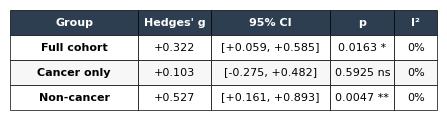

  Saved summary table to /shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/doser_summary_table.svg
  Size: 140 × 20 mm
  Font: 8 pt


In [12]:
# ══════════════════════════════════════════════════════════════════════════
# SUMMARY TABLE — separate figure
# ══════════════════════════════════════════════════════════════════════════
TABLE_SIZE_MM = (140, 20)
TABLE_FONT    = 8

plt.rcParams['svg.fonttype'] = 'none'

def plot_summary_table(summary_rows, save_path):

    col_labels = ['Group', "Hedges' g", '95% CI', 'p', 'I²']

    cell_text = []

    for r in summary_rows:
        if r is None or np.isnan(r.get('g_re', np.nan)):
            cell_text.append([r['label'], '—', '—', '—', '—'])
            continue

        cell_text.append([
            r['label'],
            f"{r['g_re']:+.3f}",
            f"[{r['ci_lo_re']:+.3f}, {r['ci_hi_re']:+.3f}]",
            f"{fmt_p(r['p_re'], label=False)} {sig_stars(r['p_re'])}",
            f"{r['I2']:.0f}%"
        ])

    fig, ax_table = plt.subplots(figsize=(TABLE_SIZE_MM[0] / 25.4, TABLE_SIZE_MM[1] / 25.4))

    ax_table.axis('off')

    tbl = ax_table.table(
        cellText=cell_text,
        colLabels=col_labels,
        loc='center',
        cellLoc='center',
        colWidths=[0.30, 0.17, 0.28, 0.15, 0.10]
    )

    tbl.auto_set_font_size(False)
    tbl.set_fontsize(TABLE_FONT)
    tbl.scale(1, 1.5)

    for (row_i, col_i), cell in tbl.get_celld().items():

        cell.set_linewidth(0.5)

        if row_i == 0:
            cell.set_facecolor('#2c3e50')
            cell.set_text_props(color='white', fontweight='bold', fontsize=TABLE_FONT)

        else:
            cell.set_facecolor('#f7f7f7' if row_i % 2 == 0 else 'white')

            if col_i == 0:
                cell.set_text_props(fontweight='bold', fontsize=TABLE_FONT)

    fig.savefig(save_path, format='svg', bbox_inches=None, pad_inches=0)

    plt.show()

    print(f"  Saved summary table to {save_path}")
    print(f"  Size: {TABLE_SIZE_MM[0]} × {TABLE_SIZE_MM[1]} mm")
    print(f"  Font: {TABLE_FONT} pt")

plot_summary_table(
    summary_rows,
    save_path=os.path.join(OUT_DIR, f'{stat}_summary_table.svg')
)

## 5. C — DoSER grouped forest + diamonds-only panel for the other stats

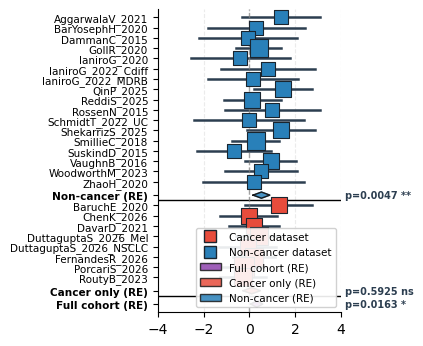

  Saved DoSER forest plot to /shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/doser_forest.svg


In [13]:
# ══════════════════════════════════════════════════════════════════════════
# FIGURE 1 — DoSER forest: non-cancer studies → non-cancer diamond →
#             cancer studies → cancer diamond → full diamond (bottom)
# ══════════════════════════════════════════════════════════════════════════
plt.rcParams['svg.fonttype'] = 'none'

def _diamond_from(ax, y, result, color, trans, **kw):
    _draw_diamond(ax, y, result.get('g_re', np.nan), result.get('ci_lo_re', np.nan),
                  result.get('ci_hi_re', np.nan), result.get('p_re', np.nan), color, trans, **kw)


def plot_forest_doser(meta_df, full_result, cancer_result, noncancer_result, save_path):
    meta_df = meta_df.copy()
    meta_df['is_cancer'] = meta_df['dataset'].apply(is_cancer)
    noncancer_studies = meta_df[~meta_df['is_cancer']].sort_values('dataset').reset_index(drop=True)
    cancer_studies    = meta_df[meta_df['is_cancer']].sort_values('dataset').reset_index(drop=True)

    n_rows = len(noncancer_studies) + 1 + len(cancer_studies) + 1 + 1  # +3 diamonds
    fig, ax = plt.subplots(figsize=(60 / 25.4, 100 / 25.4))
    trans = transforms.blended_transform_factory(ax.transAxes, ax.transData)

    row_gap = 1.0
    y = n_rows
    y_ticks, y_labels = [], []

    def _plot_study_row(row, y):
        color = CANCER_COLOR if row['is_cancer'] else NONCANCER_COLOR
        ax.plot([row['ci_lo'], row['ci_hi']], [y, y], color='#2c3e50', lw=1.8, zorder=2)
        ax.scatter(row['g'], y, marker='s', s=80 + row['pct_weight'] * 12, color=color,
                   edgecolors='#1a252f', linewidth=0.8, zorder=3)

    # ── Non-cancer studies + diamond ──
    for _, row in noncancer_studies.iterrows():
        _plot_study_row(row, y)
        y_ticks.append(y); y_labels.append(row['dataset'])
        y -= row_gap
    y -= 0.3
    _diamond_from(ax, y, noncancer_result, NONCANCER_COLOR, trans)
    y_ticks.append(y); y_labels.append('Non-cancer (RE)')
    y -= row_gap
    ax.axhline(y + row_gap / 2, color='black', lw=1.0)  # separator

    # ── Cancer studies + diamond ──
    for _, row in cancer_studies.iterrows():
        _plot_study_row(row, y)
        y_ticks.append(y); y_labels.append(row['dataset'])
        y -= row_gap
    y -= 0.3
    _diamond_from(ax, y, cancer_result, CANCER_COLOR, trans)
    y_ticks.append(y); y_labels.append('Cancer only (RE)')
    y -= row_gap
    ax.axhline(y + row_gap / 2, color='black', lw=1.0)  # separator

    # ── Full pooled diamond — always last, at the very bottom ──
    y -= 0.3
    _diamond_from(ax, y, full_result, DIAMOND_COLOR, trans)
    y_ticks.append(y); y_labels.append('Full cohort (RE)')

    ax.axvline(0, color='grey', lw=1, linestyle='--', alpha=0.7)
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels, fontsize=7.5)
    for lbl in ax.get_yticklabels():
        if lbl.get_text() in ('Non-cancer (RE)', 'Cancer only (RE)', 'Full cohort (RE)'):
            lbl.set_fontweight('bold')
    ax.set_xlim(*FOREST_XLIM)

    legend_elements = [
        plt.Line2D([0], [0], marker='s', color='w', markerfacecolor=CANCER_COLOR,
                   markeredgecolor='#1a252f', markersize=9, label='Cancer dataset'),
        plt.Line2D([0], [0], marker='s', color='w', markerfacecolor=NONCANCER_COLOR,
                   markeredgecolor='#1a252f', markersize=9, label='Non-cancer dataset'),
        Patch(facecolor=DIAMOND_COLOR,   edgecolor='#1a1a1a', alpha=0.85, label='Full cohort (RE)'),
        Patch(facecolor=CANCER_COLOR,    edgecolor='#1a1a1a', alpha=0.85, label='Cancer only (RE)'),
        Patch(facecolor=NONCANCER_COLOR, edgecolor='#1a1a1a', alpha=0.85, label='Non-cancer (RE)'),
    ]
    ax.legend(handles=legend_elements, loc='lower right', fontsize=7.5, framealpha=0.9)

    ax.yaxis.grid(False)
    ax.xaxis.grid(True, alpha=0.25, linestyle='--')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_ylim(min(y_ticks) - 0.8, max(y_ticks) + 0.8)

    fig.tight_layout()
    fig.savefig(save_path, format='svg', bbox_inches=None, pad_inches=0)
    plt.show()
    print(f"  Saved DoSER forest plot to {save_path}")


plot_forest_doser(
    stat_group_results['doser']['full']['meta_df'],
    stat_group_results['doser']['full'],
    stat_group_results['doser']['cancer'],
    stat_group_results['doser']['noncancer'],
    save_path=os.path.join(OUT_DIR, 'doser_forest.svg')
)

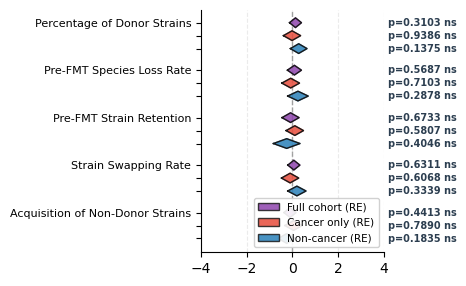

  Saved diamonds-only panel to /shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/other_stats_diamonds.svg


In [14]:
# ══════════════════════════════════════════════════════════════════════════
# FIGURE 2 — diamonds-only panel for every OTHER stat (no study squares)
# ══════════════════════════════════════════════════════════════════════════

plt.rcParams['svg.fonttype'] = 'none'

def plot_diamonds_only(stats_to_plot, stat_group_results, stat_labels, save_path):
    fig, ax = plt.subplots(figsize=(60 / 25.4, 80 / 25.4))
    trans = transforms.blended_transform_factory(ax.transAxes, ax.transData)

    group_order = [('full',      'Full cohort', DIAMOND_COLOR),
                   ('cancer',    'Cancer only', CANCER_COLOR),
                   ('noncancer', 'Non-cancer',  NONCANCER_COLOR)]

    row_gap, stat_block_gap = 0.75, 0.5
    cursor_y = 0
    y_ticks, y_labels = [], []

    for s in stats_to_plot:
        for key, _, color in group_order:
            _diamond_from(ax, cursor_y, stat_group_results[s][key] or {}, color, trans, half_h=0.28)
            y_labels.append(stat_labels.get(s, s) if key == 'full' else '')   # label only the first diamond per stat
            y_ticks.append(cursor_y)
            cursor_y -= row_gap
        cursor_y -= stat_block_gap

    ax.axvline(0, color='grey', lw=1, linestyle='--', alpha=0.7)
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels, fontsize=8)
    ax.set_xlim(*FOREST_XLIM)

    legend_elements = [
        Patch(facecolor=DIAMOND_COLOR,   edgecolor='#1a1a1a', alpha=0.85, label='Full cohort (RE)'),
        Patch(facecolor=CANCER_COLOR,    edgecolor='#1a1a1a', alpha=0.85, label='Cancer only (RE)'),
        Patch(facecolor=NONCANCER_COLOR, edgecolor='#1a1a1a', alpha=0.85, label='Non-cancer (RE)'),
    ]
    ax.legend(handles=legend_elements, loc='lower right', fontsize=7.5, framealpha=0.9)

    ax.yaxis.grid(False)
    ax.xaxis.grid(True, alpha=0.25, linestyle='--')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_ylim(min(y_ticks) - 0.8, max(y_ticks) + row_gap)

    fig.tight_layout()
    fig.savefig(save_path, format='svg', bbox_inches=None, pad_inches=0)
    plt.show()
    print(f"  Saved diamonds-only panel to {save_path}")


plot_diamonds_only(
    [s for s in OTHER_STATS if s != 'perc_strains_lost'],
    stat_group_results, STAT_LABELS,
    save_path=os.path.join(OUT_DIR, 'other_stats_diamonds.svg')
)

## 6. Per-indication subgroup summary

In [15]:
# Pooled RE estimate per stat for the full cohort and each indication → subgroup_summary.csv
subgroups = {'Full cohort': filter_heterogeneous(fmt_merged)}
for indication, subdf in fmt_merged.groupby('indication'):
    filtered = filter_heterogeneous(subdf)
    if not filtered.empty:
        subgroups[indication] = filtered

rows = []
for group_label, gdf in subgroups.items():
    for s in stats_to_test:
        if gdf[s].notna().any():
            r = meta_analyze(gdf, s)
            rows.append({'group': group_label, 'stat': s, 'g_re': r['g_re'], 'ci_lo': r['ci_lo_re'],
                         'ci_hi': r['ci_hi_re'], 'p_re': r['p_re'], 'I2': r['I2'],
                         'sig': sig_stars(r['p_re']) if not np.isnan(r['p_re']) else '—'})

subgroup_summary = (pd.DataFrame(rows)
                    .pivot_table(index='stat', columns='group', values=['g_re', 'p_re', 'sig'], aggfunc='first'))
print(subgroup_summary.to_string())
subgroup_summary.to_csv(os.path.join(SAVE_DIR, 'subgroup_summary.csv'))

                            g_re                                                          p_re                                                       sig                                                                                                      
group                      CDiff    Cancer Full cohort  IBD (CD)  IBD (UC)      MDRO     CDiff    Cancer Full cohort  IBD (CD)  IBD (UC)      MDRO CDiff Cancer Full cohort GvHD IBD (CD) IBD (UC) IBS MDRO Psoriatic arthritis TKI induced diarrhea Tourettes
stat                                                                                                                                                                                                                                                          
doser                   0.599486  0.103330    0.322410  0.234107  0.879839  0.353231  0.142983  0.592524    0.016306  0.767012  0.193242  0.516633    ns     ns           *    —       ns       ns   —   ns                   —            